# 11 - Features for Predicting `original_language`

**Goal:** build one row per movie `id` with a target (`target_original_language`) and predictor columns.

**Output:** `data/features/11_language_features.csv`

## 0. Setup

In [13]:
import ast
import numpy as np
import pandas as pd

# TODO: confirm paths resolve from notebooks/feature_engineering/
RAW = "../../data/raw/"
PROC = "../../data/processed/"
OUT = "../../data/features/11_language_features.csv"

## 1. Load sources

All sources are in `data/processed/` (produced by the preprocessing notebooks 01-05).

| Source | Columns used |
|---|---|
| `processed/movies_metadata.csv` (base) | id, release_date, budget, revenue, runtime, popularity |
| `processed/movie_text.csv` | original_language (target source), title, original_title, overview, status |
| `processed/nested_metadata.csv` | genres, production_companies, production_countries, belongs_to_collection (`A\|B\|C` text) |
| `processed/credits.csv` | director, top_five_cast, cast_size, crew_size |
| `processed/keywords_clean.csv` | keyword_names_clean (only 31,092 movies have keywords) |

Not used: `spoken_languages` (leaks the target).

In [14]:
base = pd.read_csv(PROC + "movies_metadata.csv")
print("base:", base.shape)
print(base.dtypes)

text = pd.read_csv(PROC + "movie_text.csv")
nested = pd.read_csv(
    PROC + "nested_metadata.csv",
    usecols=["id", "genres", "belongs_to_collection",
             "production_companies", "production_countries"],  # spoken_languages left out on purpose
)
credits = pd.read_csv(PROC + "credits.csv")
keywords = pd.read_csv(PROC + "keywords_clean.csv")

for name, d in [("text", text), ("nested", nested), ("credits", credits), ("keywords", keywords)]:
    print(f"{name:9s} {d.shape}  duplicate ids: {d['id'].duplicated().sum()}")

base: (45466, 6)
id              float64
release_date        str
budget              str
revenue         float64
runtime         float64
popularity      float64
dtype: object
text      (45433, 6)  duplicate ids: 0
nested    (45433, 5)  duplicate ids: 0
credits   (45432, 5)  duplicate ids: 0
keywords  (31092, 2)  duplicate ids: 0


## 2. Clean and deduplicate `id`

Duplicate-id checks on inspection: processed metadata 32 flagged by `duplicated()` (30 real extra copies plus null-id rows), raw metadata 30, raw credits 44, raw keywords 987. The other processed files (`movie_text`, `nested_metadata`, `credits`, `keywords_clean`) have 0. Merging without deduping would multiply rows.

In [15]:
n0 = len(base)
base = base.dropna(subset=["id"]).copy()
print("dropped null-id rows:", n0 - len(base))

print("duplicate-id extra rows:", base["id"].duplicated().sum())
base = (base.sort_values(["id", "popularity"], ascending=[True, False])
            .drop_duplicates("id", keep="first")
            .reset_index(drop=True))

for col in ["id", "budget", "revenue", "runtime"]:
    base[col] = pd.to_numeric(base[col], errors="raise").round().astype("Int64")

assert base["id"].is_unique
print(base.shape)
print(base.dtypes)

dropped null-id rows: 3
duplicate-id extra rows: 30
(45433, 6)
id                Int64
release_date        str
budget            Int64
revenue           Int64
runtime           Int64
popularity      float64
dtype: object


## 3. Merge onto the base dataset (left joins on `id`)

In [16]:
df = (base
      .merge(text, on="id", how="left")
      .merge(nested, on="id", how="left")
      .merge(credits, on="id", how="left")
      .merge(keywords, on="id", how="left"))

df = df.rename(columns={"top_five_cast": "top_cast", "keyword_names_clean": "keywords"})

# Merge must not add rows
assert len(df) == len(base), "merge changed the row count"
assert df["id"].is_unique
print("after merge:", df.shape)

# Drop ids with no original language
print("missing original_language:", df["original_language"].isna().sum())
df = df.dropna(subset=["original_language"]).reset_index(drop=True)
print("after dropping missing target:", df.shape)

print(df[["director", "top_cast", "cast_size", "keywords", "genres", "production_countries"]].isna().sum())

after merge: (45433, 20)
missing original_language: 11
after dropping missing target: (45422, 20)
director                  888
top_cast                    1
cast_size                   1
keywords                14337
genres                   2441
production_countries     6280
dtype: int64


## 4. Inspect language frequencies

original_language
en    32251
fr     2436
it     1529
ja     1347
de     1079
es      994
ru      826
hi      508
ko      444
zh      409
sv      383
pt      316
cn      313
fi      295
nl      248
da      224
pl      219
tr      150
cs      130
el      113
Name: count, dtype: int64
distinct languages: 89
                   count     share  cumulative_share
original_language                                   
en                 32251  0.710030          0.710030
fr                  2436  0.053630          0.763661
it                  1529  0.033662          0.797323
ja                  1347  0.029655          0.826978
de                  1079  0.023755          0.850733
es                   994  0.021884          0.872617
ru                   826  0.018185          0.890802
hi                   508  0.011184          0.901986
ko                   444  0.009775          0.911761
zh                   409  0.009004          0.920765
sv                   383  0.008432          0.929197
pt  

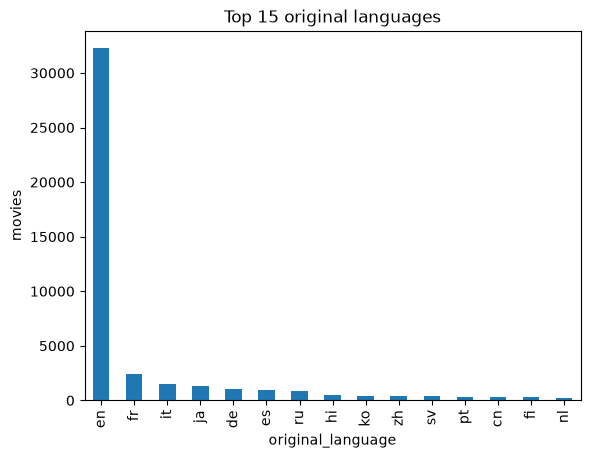

In [17]:
lang_counts = df["original_language"].value_counts()
print(lang_counts.head(20))
print("distinct languages:", len(lang_counts))

freq = lang_counts.to_frame("count")
freq["share"] = freq["count"] / freq["count"].sum()
freq["cumulative_share"] = freq["share"].cumsum()
print(freq.head(20))

print((lang_counts >= 100).sum(), "languages with >= 100 movies")
print((lang_counts >= 50).sum(),  "languages with >= 50 movies")
print((lang_counts < 10).sum(),   "languages with < 10 movies")

import matplotlib.pyplot as plt

lang_counts.head(15).plot(kind="bar")
plt.title("Top 15 original languages")
plt.ylabel("movies")
plt.show()

## 5. Build target: `target_original_language`

**Decision (TODO):** keep languages with >= N movies (or top K); group the rest as `Other`. Justify the cutoff here.

In [18]:
MIN_COUNT = 50

counts = df["original_language"].value_counts()
common = counts[counts >= MIN_COUNT].index

df["target_original_language"] = df["original_language"].where(
    df["original_language"].isin(common), "Other"
)

dist = df["target_original_language"].value_counts().to_frame("count")
dist["share"] = (dist["count"] / dist["count"].sum()).round(4)
print(dist)
print("nulls in target:", df["target_original_language"].isna().sum())

                          count   share
target_original_language               
en                        32251  0.7100
fr                         2436  0.0536
it                         1529  0.0337
ja                         1347  0.0297
de                         1079  0.0238
es                          994  0.0219
ru                          826  0.0182
Other                       562  0.0124
hi                          508  0.0112
ko                          444  0.0098
zh                          409  0.0090
sv                          383  0.0084
pt                          316  0.0070
cn                          313  0.0069
fi                          295  0.0065
nl                          248  0.0055
da                          224  0.0049
pl                          219  0.0048
tr                          150  0.0033
cs                          130  0.0029
el                          113  0.0025
no                          106  0.0023
hu                          100  0.0022


## 7. Feature engineering

### 7a. Date: `release_year`, `release_month`, `release_decade`

In [20]:
release = pd.to_datetime(df["release_date"], errors="coerce")

df["release_year"]   = release.dt.year.astype("Int64")
df["release_month"]  = release.dt.month.astype("Int64")
df["release_decade"] = (df["release_year"] // 10 * 10).astype("Int64")

print(df[["release_date", "release_year", "release_month", "release_decade"]].head())
print("missing release date:", df["release_year"].isna().sum())
print(df["release_decade"].value_counts().sort_index())

  release_date  release_year  release_month  release_decade
0   1988-10-21          1988             10            1980
1   1986-10-16          1986             10            1980
2   1995-12-09          1995             12            1990
3   1993-10-15          1993             10            1990
4   1977-05-25          1977              5            1970
missing release date: 87
release_decade
1870        2
1880        4
1890       73
1900       87
1910      176
1920      430
1930     1315
1940     1493
1950     2078
1960     2620
1970     3471
1980     3928
1990     5675
2000    11192
2010    12790
2020        1
Name: count, dtype: Int64


### 7b. Financial and numeric: `log_budget`, `log_revenue`, `runtime`, `log_popularity`


In [21]:
budget  = df["budget"].astype(float).replace(0, np.nan)
revenue = df["revenue"].astype(float).replace(0, np.nan)

df["log_budget"]     = np.log1p(budget)
df["log_revenue"]    = np.log1p(revenue)
df["log_popularity"] = np.log1p(df["popularity"])

df["runtime"] = df["runtime"].replace(0, pd.NA)

print(df[["log_budget", "log_revenue", "runtime", "log_popularity"]].describe().round(2))
print(df[["log_budget", "log_revenue", "runtime", "log_popularity"]].isna().sum())

       log_budget  log_revenue  runtime  log_popularity
count     8880.00      7398.00  43605.0        45419.00
mean        15.37        15.97     97.5            0.98
std          2.77         3.10    34.65            0.80
min          0.69         0.69      1.0            0.00
25%         14.51        14.69     86.0            0.33
50%         15.89        16.64     95.0            0.76
75%         17.03        18.02    107.0            1.54
max         19.76        21.75   1256.0            6.31
log_budget        36542
log_revenue       38024
runtime            1817
log_popularity        3
dtype: int64


### 7c. Production: `genre_count`, `has_collection`, `company_count`, `country_count`

In [22]:
df["genre_count"]    = df["genres"].str.split("|").str.len().fillna(0).astype(int)
df["company_count"]  = df["production_companies"].str.split("|").str.len().fillna(0).astype(int)
df["country_count"]  = df["production_countries"].str.split("|").str.len().fillna(0).astype(int)
df["has_collection"] = df["belongs_to_collection"].notna().astype(int)

cols = ["genre_count", "has_collection", "company_count", "country_count"]
print(df[cols].describe().round(2))
print("zeros:", (df[cols] == 0).sum())

       genre_count  has_collection  company_count  country_count
count     45422.00         45422.0       45422.00       45422.00
mean          2.00             0.1           1.55           1.09
std           1.13             0.3           1.74           0.76
min           0.00             0.0           0.00           0.00
25%           1.00             0.0           0.00           1.00
50%           2.00             0.0           1.00           1.00
75%           3.00             0.0           2.00           1.00
max           8.00             1.0          26.00          25.00
zeros: genre_count        2441
has_collection    40934
company_count     11867
country_count      6280
dtype: int64


### 7d. Credits: `cast_size`, `crew_size`, `has_director`, `director`, `top_cast`

In [24]:
df["has_director"] = df["director"].notna().astype(int)

df["cast_size"] = df["cast_size"].fillna(0).astype(int)
df["crew_size"] = df["crew_size"].fillna(0).astype(int)

print(df[["cast_size", "crew_size", "has_director"]].describe().round(2))
print(df["has_director"].value_counts())

       cast_size  crew_size  has_director
count   45422.00   45422.00      45422.00
mean       12.37      10.21          0.98
std        12.09      15.81          0.14
min         0.00       0.00          0.00
25%         6.00       2.00          1.00
50%        10.00       6.00          1.00
75%        15.00      12.00          1.00
max       313.00     435.00          1.00
has_director
1    44534
0      888
Name: count, dtype: int64


### 7e. Keywords and text: `keyword_count`, `title_word_count`, `overview_word_count`, `title_differs_from_original`

In [25]:
import ast

df["keyword_count"] = df["keywords"].apply(
    lambda x: len(ast.literal_eval(x)) if pd.notna(x) else 0
)

df["title_word_count"]    = df["title"].str.split().str.len().fillna(0).astype(int)
df["overview_word_count"] = df["overview"].str.split().str.len().fillna(0).astype(int)

df["title_differs_from_original"] = (
    df["title"].notna() & (df["title"] != df["original_title"])
).astype(int)

cols = ["keyword_count", "title_word_count", "overview_word_count", "title_differs_from_original"]
print(df[cols].describe().round(1))
print(df["title_differs_from_original"].value_counts())

       keyword_count  title_word_count  overview_word_count  \
count        45422.0           45422.0              45422.0   
mean             3.4               3.0                 53.9   
std              4.7               1.7                 35.4   
min              0.0               0.0                  0.0   
25%              0.0               2.0                 26.0   
50%              2.0               3.0                 47.0   
75%              5.0               4.0                 72.0   
max            149.0              20.0                187.0   

       title_differs_from_original  
count                      45422.0  
mean                           0.3  
std                            0.4  
min                            0.0  
25%                            0.0  
50%                            0.0  
75%                            1.0  
max                            1.0  
title_differs_from_original
0    34037
1    11385
Name: count, dtype: int64


### 7f. Modeling inputs (readable strings)

`genres`, `production_companies`, `production_countries`, `director`, `top_cast`, `keywords`, `title`, `original_title`, `overview`, `status`

In [26]:
def list_to_pipe(x):
    if pd.isna(x):
        return np.nan
    return "|".join(ast.literal_eval(x))

df["top_cast"] = df["top_cast"].apply(list_to_pipe)
df["keywords"] = df["keywords"].apply(list_to_pipe)

text_cols = ["genres", "production_companies", "production_countries", "director",
             "top_cast", "keywords", "title", "original_title", "overview", "status"]

df[text_cols] = df[text_cols].fillna("")

print(df[text_cols].head(3))
print((df[text_cols] == "").sum())

         genres                               production_companies  \
0   Drama|Crime  Villealfa Filmproduction Oy|Finnish Film Found...   
1  Drama|Comedy                        Villealfa Filmproduction Oy   
2  Crime|Comedy                         Miramax Films|A Band Apart   

       production_countries        director  \
0                   Finland  Aki Kaurismäki   
1                   Finland  Aki Kaurismäki   
2  United States of America  Allison Anders   

                                            top_cast  \
0  Turo Pajala|Susanna Haavisto|Matti Pellonpää|E...   
1  Matti Pellonpää|Kati Outinen|Sakari Kuosmanen|...   
2  Tim Roth|Antonio Banderas|Jennifer Beals|Madon...   

                                            keywords                title  \
0  underdog|prison|factory worker|prisoner|helsin...                Ariel   
1       salesclerk|helsinki|garbage|independent film  Shadows in Paradise   
2  hotel|new year's eve|witch|bet|hotel room|sper...           Four Rooms 

### 7g. Additional justified features


In [27]:
raw_extra = pd.read_csv(RAW + "movies_metadata.csv", usecols=["id", "tagline"], dtype=str)

raw_extra["id"] = pd.to_numeric(raw_extra["id"], errors="coerce")
raw_extra = raw_extra.dropna(subset=["id"])
raw_extra["id"] = raw_extra["id"].astype(int)
raw_extra = raw_extra.drop_duplicates("id")

n_before = len(df)
df = df.merge(raw_extra, on="id", how="left")
assert len(df) == n_before, "merge changed the row count"

df["has_tagline"] = df["tagline"].notna().astype(int)
df = df.drop(columns=["tagline"])        # we only need the flag

print(df[["has_tagline"]].mean().round(3))

has_tagline    0.449
dtype: float64


## 8. Final dataset and checks

In [28]:
text_cols = ["genres", "production_companies", "production_countries", "director",
             "top_cast", "keywords", "title", "original_title", "overview", "status"]

final_cols = (
    ["id", "target_original_language"]
    + ["release_year", "release_month", "release_decade"]
    + ["log_budget", "log_revenue", "runtime", "log_popularity"]
    + ["genre_count", "has_collection", "company_count", "country_count"]
    + ["cast_size", "crew_size", "has_director"]
    + ["keyword_count", "title_word_count", "overview_word_count", "title_differs_from_original"]
    + ["has_tagline"]
    + text_cols
)

final = df[final_cols].copy()

# Checks
assert final["id"].is_unique, "duplicate ids"
assert final["target_original_language"].notna().all(), "missing target"
assert "original_language" not in final.columns, "target leak"

print("shape:", final.shape)
print("\nmissing values:")
print(final.isna().sum()[lambda s: s > 0])
print("\ndtypes:")
print(final.dtypes)
print("\ntarget distribution:")
print(final["target_original_language"].value_counts())

shape: (45422, 31)

missing values:
release_year         87
release_month        87
release_decade       87
log_budget        36542
log_revenue       38024
runtime            1817
log_popularity        3
dtype: int64

dtypes:
id                               Int64
target_original_language           str
release_year                     Int64
release_month                    Int64
release_decade                   Int64
log_budget                     float64
log_revenue                    float64
runtime                          Int64
log_popularity                 float64
genre_count                      int64
has_collection                   int64
company_count                    int64
country_count                    int64
cast_size                        int64
crew_size                        int64
has_director                     int64
keyword_count                    int64
title_word_count                 int64
overview_word_count              int64
title_differs_from_original      

## 9. Save

In [29]:
import os; os.makedirs(os.path.dirname(OUT), exist_ok=True)
df.to_csv(OUT, index=False)